# The burden model without the context cascade

The reported model (`sv_burden_model.ipynb`) gives every SV event **one** genomic context, by first match:
`CDS > UTR > intron > TE > promoter ≤ 1 kb > intergenic`. That rule has two costs:

**It decides one in seven labels by fiat.** 13.8 % of the events entering the model overlap more than one
annotation layer. For those the class is the cascade's choice, not the annotation's — and the ordering
that matters most, TE above promoter, has no biological justification.

**It turns two classes into residuals.** `promoter` and `intergenic` are 100 % single-layer *by
construction*: anything also in a gene or a TE was claimed upstream. So "promoter" does not mean "in a
promoter", it means **"in a promoter and in nothing else"**.

**Here the cascade is dropped.** Every event contributes to every layer it overlaps — a deletion hitting
CDS and UTR counts once in each. Each burden now answers *how many SVs touch this class*, which is the
question the biology actually poses. `intergenic` keeps its meaning under both schemes: events overlapping
no annotation layer at all.

```r
y ~ snp_CDS + sv_CDS + sv_UTR + sv_intron + sv_TE + sv_promoter + sv_intergenic + cactus
    + sv_ctx:bio1c   for each of the six contexts
    + obio1c + obio1c:bio1c
    + (1 | garden) + (1 | kin) + (0 + obio1c | garden)
    + (0 + sv_ctx | garden)   for each of the six contexts
```

Identical to the reported model in every respect except how the burdens are counted.

⚠ **This is not free.** Overlapping burdens are more correlated than disjoint ones, so the coefficients
are less separable, not more. §1 measures exactly how much worse. The gain is interpretive — no arbitrary
ordering — not statistical.

In [1]:

import os, glob
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({"figure.dpi":120,"font.size":8,"axes.linewidth":0.6,"savefig.bbox":"tight","legend.frameon":False})
G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive")); os.makedirs(f"{G}/plots",exist_ok=True)
# colours: insertions forest green, deletions orange, SNPs grey; dark -> light = coding -> promoter -> intergenic
# (no blue or red: those are the garden-temperature scale)
PAL={"snp_CDS":"0.25","snp_promoter":"0.45","snp_intergenic":"0.65",
     "ins_CDS":"#2F4A1F","ins_promoter":"#4E6B3A","ins_intergenic":"#9DB58C",
     "del_CDS":"#B04A00","del_promoter":"#F07A2E","del_intergenic":"#F8BE91"}; PC=lambda t: PAL[t.split(":")[0]]         # colour of a term (interactions take their term's colour)
def style(a,axis="x"):
    a.set_axisbelow(True); a.grid(color="0.9",lw=0.6,axis=axis)
    for s_ in a.spines.values(): s_.set_visible(False)
def panel(a,letter,x=-0.08,y=1.04): a.annotate(letter,xy=(x,y),xycoords="axes fraction",fontsize=11,fontweight="bold",ha="right")
M="\u2212"
def pct(v,d=3): return f"{v:+.{d}g}%".replace("-",M)
NBPLOTS=os.path.join(os.getcwd(),"plots"); os.makedirs(NBPLOTS,exist_ok=True)          # notebooks/plots/, for the figures kept with the notebook
def save(fig,name,nb=False):
    for d in ([f"{G}/plots"]+([NBPLOTS] if nb else [])):
        fig.savefig(f"{d}/{name}.png",dpi=200,bbox_inches="tight"); fig.savefig(f"{d}/{name}.pdf",bbox_inches="tight")


In [2]:

PA=f"{G}/final_models_pooled_all"
CTX=["CDS","UTR","intron","TE","promoter","intergenic"]
CC={"CDS":"#2F4A1F","UTR":"#4E6B3A","intron":"#7E9B6B","TE":"#C46A10",
    "promoter":"#5B7A99","intergenic":"#B9B9B9"}
CI,CD="#2F4A1F","#B04A00"
def arm(tag):
    S=f"_x_obio1cobio1cbio1c_re0obio1cgarden_all6_refid_intall{tag}"
    sc=pd.read_csv(f"{PA}/pooled_rate_scale_x_obio1cobio1cbio1c_all6{tag}.csv").set_index("context")
    o={"co":pd.read_csv(f"{PA}/coef_M2p_reml{S}.csv").set_index("term"),
       "V":pd.read_csv(f"{PA}/vcov_M2p_reml{S}.csv",index_col=0),"sc":sc,
       "ll":pd.read_csv(f"{PA}/loglik_M2p_reml{S}.csv").iloc[0],"suf":S}
    o["pv"]={f"sv_{c}":100/(sc.loc[c,"sd_rate"]*sc.loc[c,"med_called"]) for c in sc.index}
    g=lambda n: pd.read_csv(f"{PA}/loglik_{n}{S}.csv").logLik[0]
    o["LRT"]={f"sv_{c}": stats.chi2.sf(2*(g("M2p_ml")-g(f"M2p_ml_drop_sv_{c}")),1) for c in CTX}
    return o
OC,CAS=arm("_overcount"),arm("")
BO=pd.read_csv(f"{G}/founder_burden_event_overcount.csv",dtype={"founder":str})
BC=pd.read_csv(f"{G}/founder_burden_event.csv",dtype={"founder":str})
E=pd.read_csv(f"{G}/sv_event_catalog.csv"); AP=E[E.passes.astype(bool)]
print(f"events entering the model: {len(AP):,}")
print(f"  overcount logLik {OC['ll'].logLik:.2f} (df {int(OC['ll'].df)}, singular {OC['ll'].singular})")
print(f"  cascade   logLik {CAS['ll'].logLik:.2f} (df {int(CAS['ll'].df)}, singular {CAS['ll'].singular})")
print("  (not comparable by likelihood -- different response-side counting, same y)")


events entering the model: 18,418
  overcount logLik -11077.89 (df 27, singular True)
  cascade   logLik -11080.15 (df 27, singular True)
  (not comparable by likelihood -- different response-side counting, same y)


## 1 · What the two counting schemes give

**(a)** Events per context under each scheme, split by insertions and deletions. Under the cascade the
bars sum to the event total, because every event is in exactly one class. Under overcounting they sum to
*more* — that is the point: an event in CDS and UTR appears in both.

**(b)** What it costs. Overlapping burdens are more correlated than disjoint ones, and the independent
variance of each burden — the part not predictable from the other five — is what the model has to work
with. The bars are that independent share under each scheme.

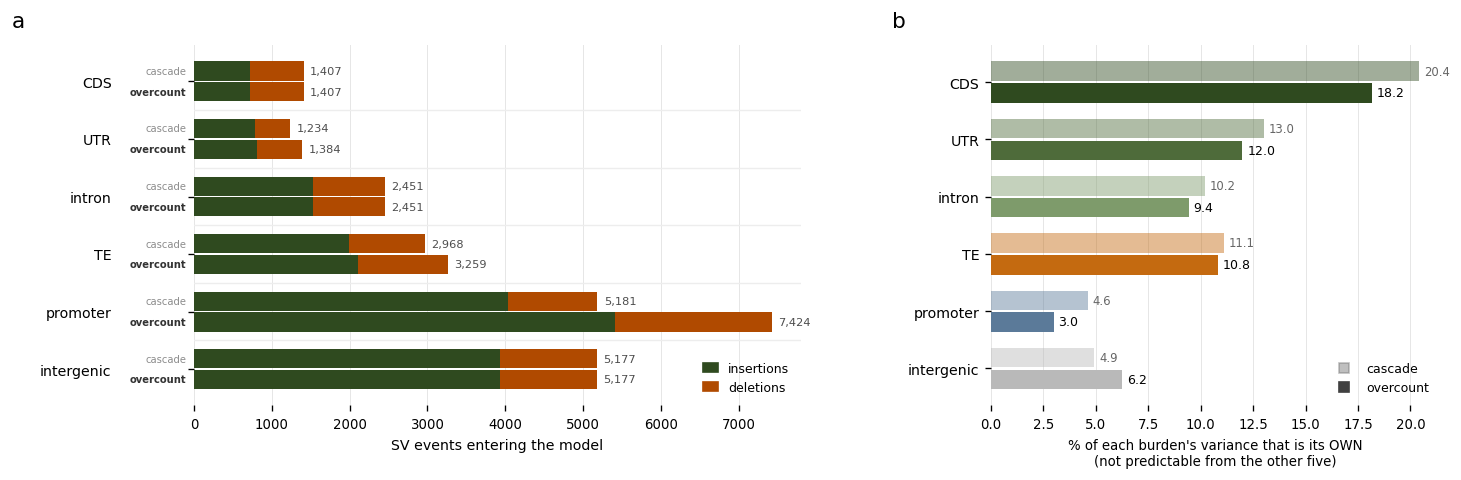

EVENTS PER CONTEXT, the two schemes

            cascade  overcount  extra
CDS            1407       1407      0
UTR            1234       1384    150
intron         2451       2451      0
TE             2968       3259    291
promoter       5181       7424   2243
intergenic     5177       5177      0
TOTAL         18418      21102   2684

  18,418 events, counted 21,102 times under overcounting -- 1.15 classes per event on average.


INDEPENDENT VARIANCE OF EACH BURDEN (%)

            cascade  overcount  change
CDS            20.4       18.2    -2.2
UTR            13.0       12.0    -1.0
intron         10.2        9.4    -0.8
TE             11.1       10.8    -0.3
promoter        4.6        3.0    -1.6
intergenic      4.9        6.2     1.3


In [3]:

LAY=["CDS","UTR","intron","TE","promoter"]
OVER={c:(AP[f"L_{c}"].astype(bool) if c!="intergenic"
         else ~AP[[f"L_{l}" for l in LAY]].any(axis=1)) for c in CTX}
fig,ax=plt.subplots(1,2,figsize=(13.4,3.9),gridspec_kw=dict(width_ratios=[1.35,1],wspace=0.36))
a=ax[0]; style(a); h=0.36
for i,c in enumerate(CTX):
    for j,(sel,lab) in enumerate(((AP.context==c,"cascade"),(OVER[c],"overcount"))):
        ni=int((sel&AP.kind.eq("ins")).sum()); nd=int((sel&AP.kind.eq("del")).sum())
        y=i+(j-0.5)*h
        a.barh(y,ni,height=h*0.92,color=CI,lw=0)
        a.barh(y,nd,height=h*0.92,left=ni,color=CD,lw=0)
        a.annotate(f"{ni+nd:,}",xy=(ni+nd,y),xytext=(4,0),textcoords="offset points",
                   va="center",fontsize=6.8,color="0.3")
    a.annotate("cascade",xy=(-0.012,i-0.5*h),xycoords=("axes fraction","data"),ha="right",
               va="center",fontsize=6,color="0.55")
    a.annotate("overcount",xy=(-0.012,i+0.5*h),xycoords=("axes fraction","data"),ha="right",
               va="center",fontsize=6,color="0.2",fontweight="bold")
    if i<len(CTX)-1: a.axhline(i+0.5,color="0.93",lw=0.8)
a.set_yticks(range(len(CTX))); a.set_yticklabels(CTX,fontsize=8.5)
a.tick_params(axis="y",pad=46); a.invert_yaxis()
a.set_xlabel("SV events entering the model",fontsize=8.5)
a.legend([plt.Rectangle((0,0),1,1,color=CI),plt.Rectangle((0,0),1,1,color=CD)],
         ["insertions","deletions"],fontsize=7.5,loc="lower right",handlelength=1.2)
a.annotate("a",xy=(-0.30,1.05),xycoords="axes fraction",fontsize=13)
a=ax[1]; style(a)
def indep(B):
    zz=lambda v:(v-v.mean())/v.std(ddof=1)
    X=np.column_stack([zz((B[f"ins_all_{c}_all"]+B[f"del_all_{c}_all"])
                          /(B[f"called_ins_all_{c}_all"]+B[f"called_del_all_{c}_all"])) for c in CTX])
    out=[]
    for i in range(len(CTX)):
        oth=np.delete(X,i,axis=1); A_=np.column_stack([np.ones(len(X)),oth])
        r=X[:,i]-A_@np.linalg.lstsq(A_,X[:,i],rcond=None)[0]
        out.append(100*r.var()/X[:,i].var())
    return np.array(out)
IC,IO=indep(BC),indep(BO)
for i,c in enumerate(CTX):
    a.barh(i-0.19,IC[i],height=0.34,color=CC[c],lw=0,alpha=0.45)
    a.barh(i+0.19,IO[i],height=0.34,color=CC[c],lw=0)
    a.annotate(f"{IC[i]:.1f}",xy=(IC[i],i-0.19),xytext=(3,0),textcoords="offset points",
               va="center",fontsize=7,color="0.4")
    a.annotate(f"{IO[i]:.1f}",xy=(IO[i],i+0.19),xytext=(3,0),textcoords="offset points",
               va="center",fontsize=7.5)
a.set_yticks(range(len(CTX))); a.set_yticklabels(CTX,fontsize=8.5); a.invert_yaxis()
a.set_xlabel("% of each burden's variance that is its OWN\n(not predictable from the other five)",fontsize=8)
a.plot([],[],"s",color="0.45",ms=6,alpha=0.45); a.plot([],[],"s",color="0.25",ms=6)
a.legend(["cascade","overcount"],fontsize=7.5,loc="lower right")
a.annotate("b",xy=(-0.22,1.05),xycoords="axes fraction",fontsize=13)
save(fig,"overcount_counts",nb=True); plt.show()
print("EVENTS PER CONTEXT, the two schemes\n")
T=pd.DataFrame({"cascade":[int((AP.context==c).sum()) for c in CTX],
                "overcount":[int(OVER[c].sum()) for c in CTX]},index=CTX)
T["extra"]=T.overcount-T.cascade
T.loc["TOTAL"]=T.sum()
print(T.to_string())
print(f"\n  {len(AP):,} events, counted {int(T.loc['TOTAL','overcount']):,} times under overcounting "
      f"-- {T.loc['TOTAL','overcount']/len(AP):.2f} classes per event on average.\n")
print("\nINDEPENDENT VARIANCE OF EACH BURDEN (%)\n")
print(pd.DataFrame({"cascade":IC.round(1),"overcount":IO.round(1),
                    "change":(IO-IC).round(1)},index=CTX).to_string())


## 2 · The model, counted both ways

Burden main effects, then the garden-temperature interactions. Cascade on the left of each pair,
overcount on the right. Filled markers are p < 0.05.

The question is simple: **does any conclusion depend on the counting scheme?**

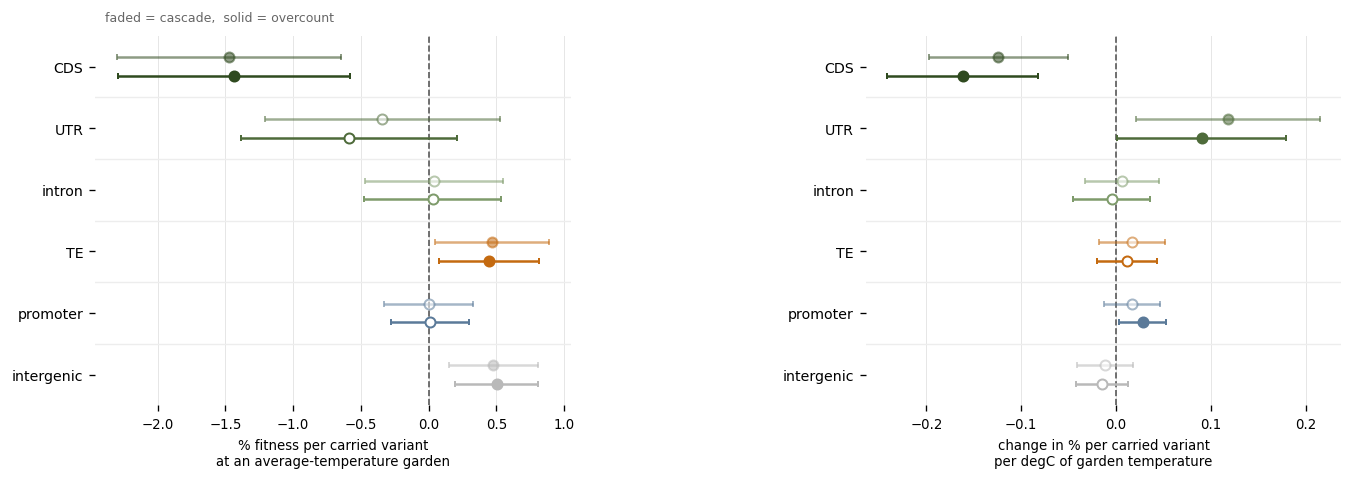


BURDEN MAIN EFFECTS, % fitness per carried variant

   context              cascade           overcount
       CDS -1.4728 (p 0.000488) -1.4351 (p 0.00102)
       UTR    -0.3405 (p 0.442)   -0.5874 (p 0.149)
    intron    +0.0383 (p 0.883)   +0.0288 (p 0.911)
        TE   +0.4672 (p 0.0301)  +0.4430 (p 0.0187)
  promoter    -0.0008 (p 0.996)   +0.0114 (p 0.938)
intergenic  +0.4766 (p 0.00434) +0.5013 (p 0.00133)

GARDEN-TEMPERATURE INTERACTIONS, % per carried variant per degC (LRT p)

   context             cascade           overcount
       CDS -0.1240 (p 0.00166) -0.1617 (p 0.00016)
       UTR  +0.1181 (p 0.0155)  +0.0902 (p 0.0476)
    intron   +0.0060 (p 0.763)  -0.0047 (p 0.0646)
        TE   +0.0170 (p 0.336)   +0.0114 (p 0.482)
  promoter   +0.0172 (p 0.253)  +0.0280 (p 0.0308)
intergenic   -0.0118 (p 0.428)   -0.0148 (p 0.288)


PER SD OF BURDEN -- the model's own scale

   context           cascade         overcount
       CDS -0.2823 +- 0.0809 -0.2751 +- 0.0838
       UTR -0

In [4]:

fig,axs=plt.subplots(1,2,figsize=(13.4,4.0),gridspec_kw=dict(wspace=0.62))
for a,(kind,lab) in zip(axs,(("main","% fitness per carried variant\nat an average-temperature garden"),
                             ("inter","change in % per carried variant\nper degC of garden temperature"))):
    style(a); a.axvline(0,color="0.35",lw=1,ls="--")
    for i,c in enumerate(CTX):
        t=f"sv_{c}"
        for j,(o,nm) in enumerate(((CAS,"cascade"),(OC,"overcount"))):
            n=t if kind=="main" else f"{t}:bio1c"
            k=o["pv"][t]; e,se=o["co"].loc[n,"estimate"]*k,o["co"].loc[n,"se"]*k
            p=o["co"].loc[n,"p"] if kind=="main" else o["LRT"][t]
            y=i+(j-0.5)*0.30
            a.errorbar(e,y,xerr=1.96*se,fmt="o",color=CC[c],mfc=CC[c] if p<0.05 else "white",
                       mew=1.2,ms=6,capsize=2,zorder=3,alpha=1.0 if j else 0.55)
        if i<len(CTX)-1: a.axhline(i+0.5,color="0.93",lw=0.8)
    a.set_yticks(range(len(CTX))); a.set_yticklabels(CTX,fontsize=8.5)
    a.set_ylim(len(CTX)-0.5,-0.5); a.set_xlabel(lab,fontsize=8)
axs[0].annotate("faded = cascade,  solid = overcount",xy=(0.02,1.04),xycoords="axes fraction",
                fontsize=7.5,color="0.4")
save(fig,"overcount_vs_cascade",nb=True); plt.show()
for kind,hdr in (("main","BURDEN MAIN EFFECTS, % fitness per carried variant"),
                 ("inter","GARDEN-TEMPERATURE INTERACTIONS, % per carried variant per degC (LRT p)")):
    print(f"\n{hdr}\n")
    rows=[]
    for c in CTX:
        t=f"sv_{c}"; r={"context":c}
        for o,nm in ((CAS,"cascade"),(OC,"overcount")):
            n=t if kind=="main" else f"{t}:bio1c"; k=o["pv"][t]
            p=o["co"].loc[n,"p"] if kind=="main" else o["LRT"][t]
            r[nm]=f"{o['co'].loc[n,'estimate']*k:+.4f} (p {p:.3g})"
        rows.append(r)
    print(pd.DataFrame(rows).to_string(index=False))
print("\n\nPER SD OF BURDEN -- the model's own scale\n")
print(pd.DataFrame([{"context":c,
    "cascade":f"{CAS['co'].loc['sv_'+c,'estimate']:+.4f} +- {CAS['co'].loc['sv_'+c,'se']:.4f}",
    "overcount":f"{OC['co'].loc['sv_'+c,'estimate']:+.4f} +- {OC['co'].loc['sv_'+c,'se']:.4f}"}
    for c in CTX]).to_string(index=False))


## 3 · Reading it

Overcounting removes the one genuinely arbitrary choice in the context assignment — the TE-above-promoter
ordering — at the price of burdens that overlap and are therefore harder to separate. §1 quantifies both
sides of that trade; §2 shows which conclusions survive it.

**What to check against the cascade model.** The coding effect is the headline, and it should be the least
affected: coding events are the least likely to be reclassified by dropping the cascade, since CDS already
sits at the top of it. The classes that change most are the ones the cascade was deciding — TE and
promoter, which exchange the events that overlap both.

⚠ **Overcounting is not a fix for collinearity — it makes it worse.** Any class whose independent variance
falls in §1 is estimated on less information than before. A coefficient that moves between the schemes is
telling you it was never well identified, not that one scheme is right.

⚠ **Neither scheme addresses what an insertion brings.** Both label a variant by what it overlaps in
TAIR10 — the landing site. An insertion carrying a TE into intergenic sequence is "intergenic" under both.
That is a separate axis, and the catalogue's `seq_class` / `te_family` columns are where it would be
taken up.

## As run

- **Burdens.** `_sv_burden_build.py` with `CTX_MODE=overcount SV_UNIT=event`, which tags its outputs
  `_overcount`. In that mode the per-record annotation-layer masks replace the cascade label, so an event
  is added to every layer it overlaps; `intergenic` is defined as overlapping no layer, identically to the
  cascade. Every other filter is unchanged: call rate ≥ 90 %, ≥ 2 carriers, truvari events, ins+del pooled.
- **Fits.** `_sv_burden_pooled_models.R` with `POOL_SET=all6 INTER_SET=all CRTAG=_overcount`,
  `EXTRA_FIXED="obio1c + obio1c:bio1c"`, `EXTRA_RE="(0 + obio1c | garden)"`, `RE_DROP=fid`, tasks 0–8.
- **Not comparable by likelihood.** The two schemes build different predictors from the same response, so
  their log-likelihoods are not on a common footing and no model-selection statistic applies. The
  comparison is of coefficients and of what each burden is made of.
- **Layer membership** comes from `sv_event_catalog.csv` (`L_CDS` … `L_promoter`), computed inside the
  catalogue builder so it is row-aligned with `passes` by construction.